In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
from glob import glob

In [2]:
# Load the data, if there is 
wt_cen4_dfs = [pd.read_csv(f) for f in glob('high_speed_trajectories/YV3670/*.csv')]
wt_cen15_dfs = [pd.read_csv(f) for f in glob('high_speed_trajectories/YV4228/*.csv')]
cin8RK_cen4_dfs = [pd.read_csv(f) for f in glob('high_speed_trajectories/YV3663/*.csv')]
cin8RK_cen15_dfs = [pd.read_csv(f) for f in glob('high_speed_trajectories/YV4235/*.csv')]

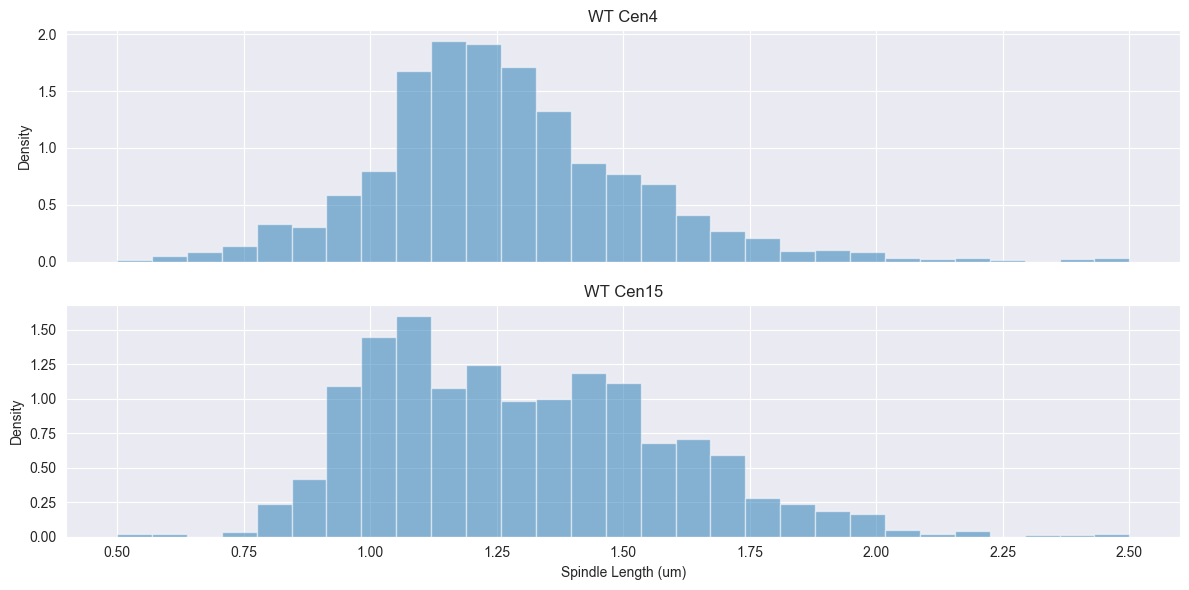

In [3]:
def plot_distribution(dfs, parameter='Spindle Length (um)', ax=None, bins=None): 
    if ax is None: # Set the axis were plotting on if none is provided to this function.
        fig, ax = plt.subplots(figsize=(6, 4))
    if bins is None: # Set the bins for the histogram if none is provided to this function.
        bins = np.linspace(0.5, 2.5, 30)
    spindle_lengths = [] # The list of spindle lengths to plot.
    for df in dfs: # Iterate over all of the dataframes and collect the spindle lengths into a single list.
        spindle_lengths.extend(df[parameter].values)
    ax.hist(spindle_lengths, bins=bins, density=True, alpha=0.5) # Plot the histogram of spindle lengths on the provided axis.
    ax.set_ylabel('Density') # Set the Y label of the axis to 'Density'.
    return ax # Return the axis so the user can manually modify it if they want to.

fig, axs = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
plot_distribution(wt_cen4_dfs, ax=axs[0])
axs[0].set_title('WT Cen4')
plot_distribution(wt_cen15_dfs, ax=axs[1])
axs[1].set_title('WT Cen15')
axs[1].set_xlabel('Spindle Length (um)')
plt.tight_layout()

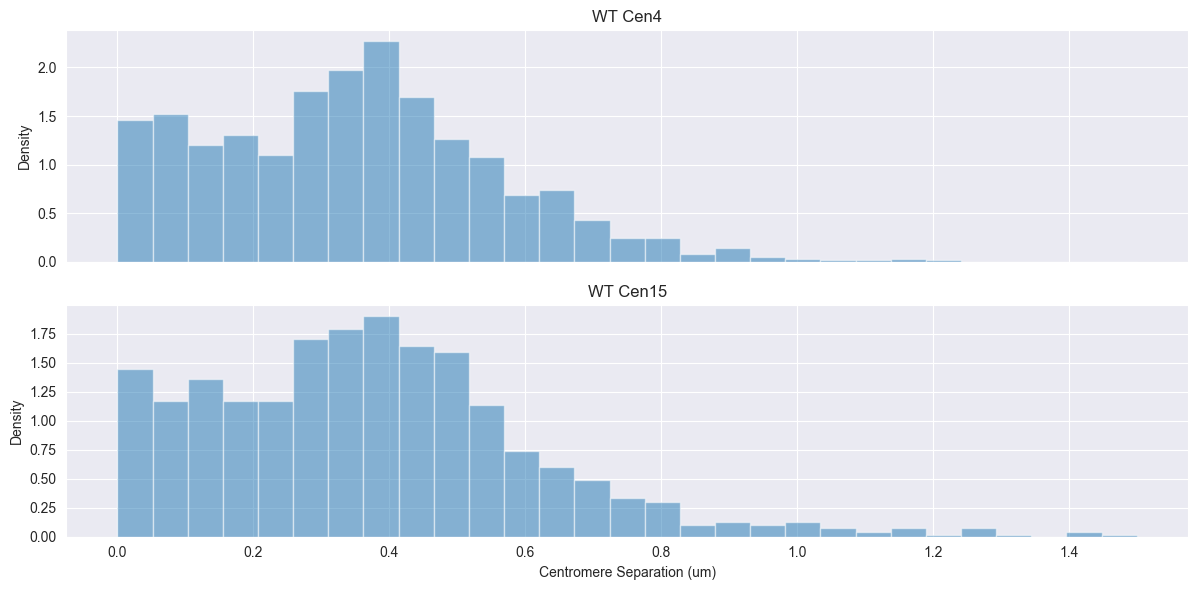

In [4]:
fig, axs = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
plot_distribution(wt_cen4_dfs, ax=axs[0], parameter='Centromere Separation (um)', bins=np.linspace(0, 1.5, 30))
axs[0].set_title('WT Cen4')
plot_distribution(wt_cen15_dfs, ax=axs[1], parameter='Centromere Separation (um)', bins=np.linspace(0, 1.5, 30))
axs[1].set_title('WT Cen15')
axs[1].set_xlabel('Centromere Separation (um)')
plt.tight_layout()

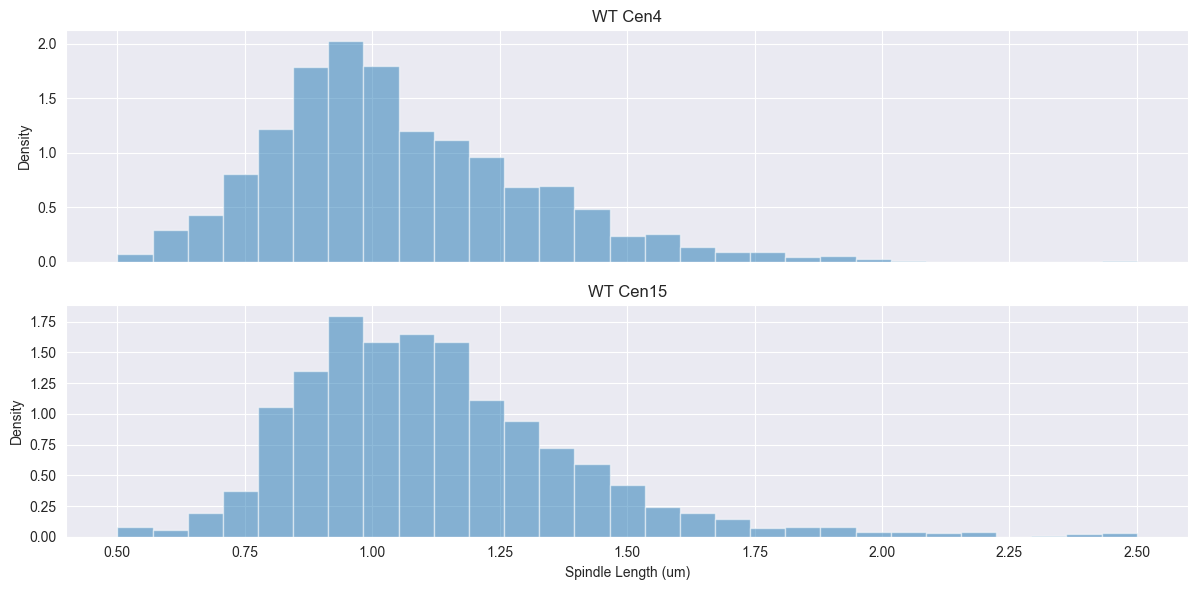

In [5]:
fig, axs = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
plot_distribution(cin8RK_cen4_dfs, ax=axs[0])
axs[0].set_title('WT Cen4')
plot_distribution(cin8RK_cen15_dfs, ax=axs[1])
axs[1].set_title('WT Cen15')
axs[1].set_xlabel('Spindle Length (um)')
plt.tight_layout()

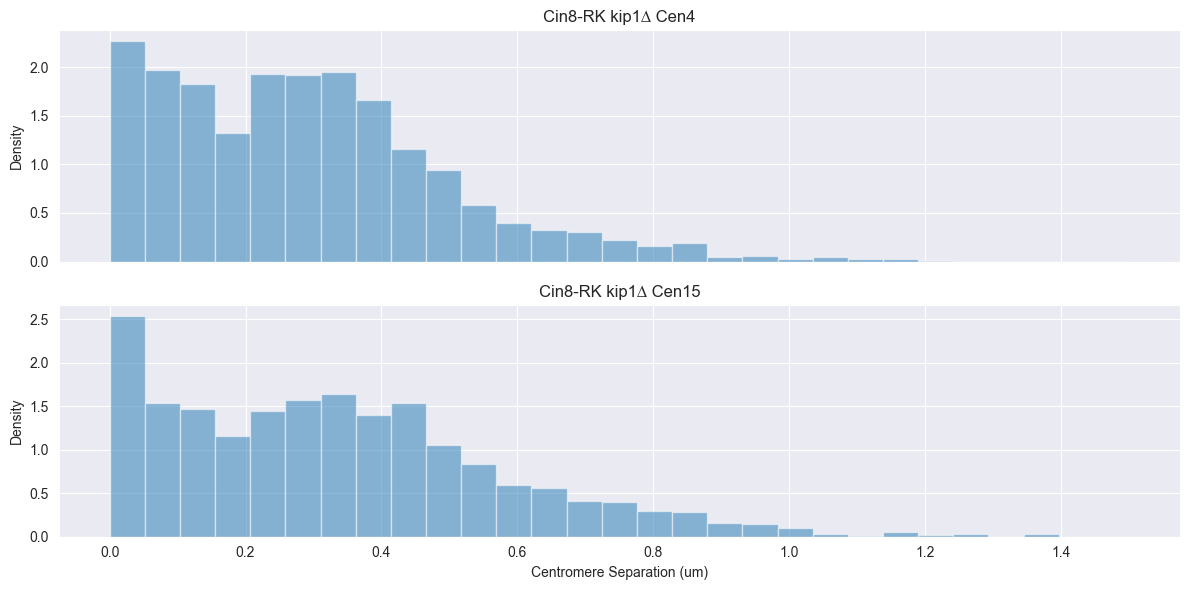

In [6]:
fig, axs = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
plot_distribution(cin8RK_cen4_dfs, ax=axs[0], parameter='Centromere Separation (um)', bins=np.linspace(0, 1.5, 30))
axs[0].set_title('Cin8-RK kip1∆ Cen4')
plot_distribution(cin8RK_cen15_dfs, ax=axs[1], parameter='Centromere Separation (um)', bins=np.linspace(0, 1.5, 30))
axs[1].set_title('Cin8-RK kip1∆ Cen15')
axs[1].set_xlabel('Centromere Separation (um)')
plt.tight_layout()

In [37]:
from scipy.stats import mannwhitneyu

mannwhitneyu(
    np.concatenate([df['Centromere Separation (um)'].dropna().values for df in wt_cen4_dfs]),
    np.concatenate([df['Centromere Separation (um)'].dropna().values for df in cin8RK_cen4_dfs]),
    alternative='two-sided'
)

MannwhitneyuResult(statistic=np.float64(1535558.0), pvalue=np.float64(1.3432857025990379e-18))

# Compare the distribution of Centromere Separations between the WT and Cin8-RK kip1∆ strains for both Cen4 and Cen15.

In [7]:
cen4_df = pd.concat([
    pd.concat(wt_cen4_dfs, ignore_index=True).assign(Strain='WT'),
    pd.concat(cin8RK_cen4_dfs, ignore_index=True).assign(Strain='Cin8-RK kip1∆')
])
cen4_df

,Centromere Separation (um),Spindle Length (um),Time (sec),Tension Classification,Strain
0,NaN,1.696811,0,NaN,WT
1,NaN,1.984887,5,NaN,WT
2,NaN,1.686956,10,NaN,WT
3,NaN,1.615293,15,NaN,WT
4,NaN,1.838167,20,NaN,WT
...,...,...,...,...,...
1703,0.347042,1.096019,280,Low Tension,Cin8-RK kip1∆
1704,0.302082,1.108376,285,Low Tension,Cin8-RK kip1∆
1705,0.300275,1.174711,290,Low Tension,Cin8-RK kip1∆
1706,0.365374,NaN,295,Low Tension,Cin8-RK kip1∆


In [8]:
from scipy.stats import gaussian_kde
def log_kde(data, grid, bw_adjust=1.0):
    data = np.asarray(data, float)
    kde = gaussian_kde(np.log(data))
    kde.set_bandwidth(kde.factor * bw_adjust)
    return kde(np.log(grid)) / grid   # 1/x Jacobian

(0.0, 1.2)

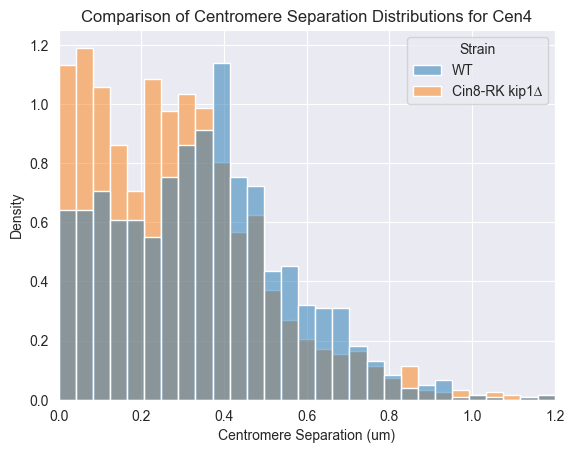

In [9]:
import seaborn as sns
sns.histplot(data=cen4_df.dropna(), x='Centromere Separation (um)', hue='Strain', kde=False, stat='density', bins=np.linspace(0, 1.2, 30))
plt.title("Comparison of Centromere Separation Distributions for Cen4")
plt.xlim(0, 1.2)

In [10]:
cen15_df = pd.concat([
    pd.concat(wt_cen15_dfs, ignore_index=True).assign(Strain='WT'),
    pd.concat(cin8RK_cen15_dfs, ignore_index=True).assign(Strain='Cin8-RK kip1∆')
])
cen15_df

,Centromere Separation (um),Spindle Length (um),Time (sec),Tension Classification,Strain
0,0.477684,0.996300,0,Low Tension,WT
1,0.466693,1.035953,5,Low Tension,WT
2,0.402723,0.994824,10,Low Tension,WT
3,0.348529,1.030936,15,Low Tension,WT
4,0.469573,1.018321,20,Low Tension,WT
...,...,...,...,...,...
1703,0.532288,NaN,280,Low Tension,Cin8-RK kip1∆
1704,0.307162,1.311396,285,Low Tension,Cin8-RK kip1∆
1705,0.326264,1.360856,290,Low Tension,Cin8-RK kip1∆
1706,0.421302,1.305633,295,Low Tension,Cin8-RK kip1∆


(0.0, 1.2)

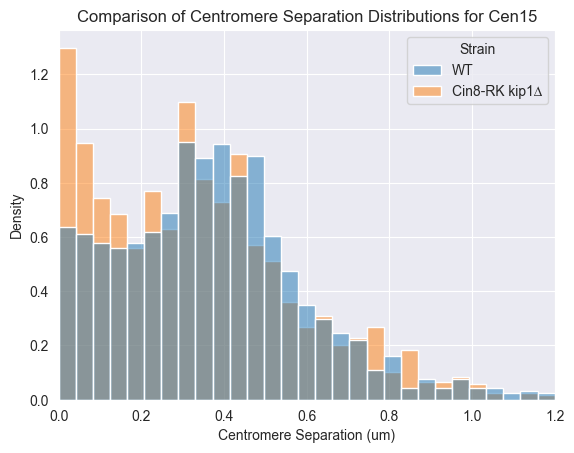

In [11]:
sns.histplot(data=cen15_df.dropna(), x='Centromere Separation (um)', hue='Strain', kde=False, stat='density', bins=np.linspace(0, 1.2, 30))
plt.title("Comparison of Centromere Separation Distributions for Cen15")
plt.xlim(0, 1.2)

# Compare the re-attachment time distributions between the WT and Cin8-RK kip1∆ strains for both Cen4 and Cen15.

In [12]:
def extract_no_tension_runs(processed_dfs, state_col='Tension Classification', spindle_col='Spindle Length (um)', time_col='Time (sec)'):
    """Find continuous runs of 'No Tension' that don't touch the start or end
    of a trajectory.

    Returns a DataFrame with columns: run_duration_sec, mean_spindle_length.
    """
    records = []
    for df in processed_dfs:
        states = df[state_col].values
        spindle = df[spindle_col].values
        times = df[time_col].values
        n = len(states)

        # Find indices where state is 'No Tension'
        is_no_tension = np.array([s == 'No Tension' if pd.notna(s) else False for s in states])

        # Find run boundaries
        i = 0
        while i < n:
            if not is_no_tension[i]:
                i += 1
                continue
            # Start of a run
            start = i
            while i < n and is_no_tension[i]:
                i += 1
            end = i  # exclusive
            # Skip runs that touch the beginning or end of the timeline
            if start == 0 or end == n:
                continue
            # Duration in seconds using the Time column
            run_duration = times[end - 1] - times[start]
            run_spindle = spindle[start:end]
            run_spindle = run_spindle[~pd.isna(run_spindle)]
            mean_spindle = np.mean(run_spindle) if len(run_spindle) > 0 else np.nan
            records.append({'run_duration_sec': run_duration, 'mean_spindle_length': mean_spindle})

    return pd.DataFrame(records)

Text(0.5, 1.0, 'Distribution of Re-attachment Times for WT Cen4')

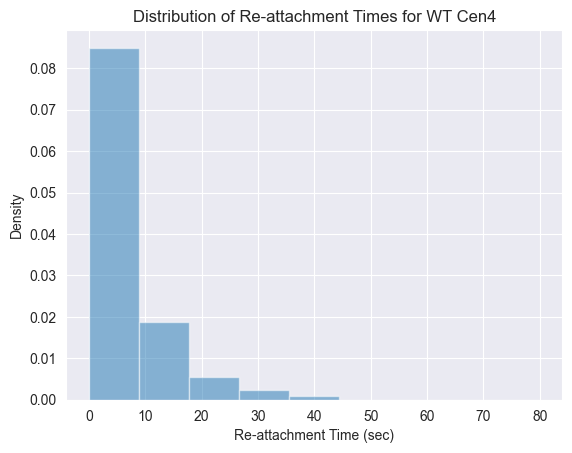

In [13]:
cen4_wt_reattachment_times = extract_no_tension_runs(wt_cen4_dfs)
plt.hist(cen4_wt_reattachment_times['run_duration_sec'], bins=np.linspace(0, 80, 10), density=True, alpha=0.5, label='WT Cen4')
plt.xlabel('Re-attachment Time (sec)')
plt.ylabel('Density')
plt.title('Distribution of Re-attachment Times for WT Cen4')

Text(0.5, 1.0, 'Distribution of Re-attachment Times for WT Cen15')

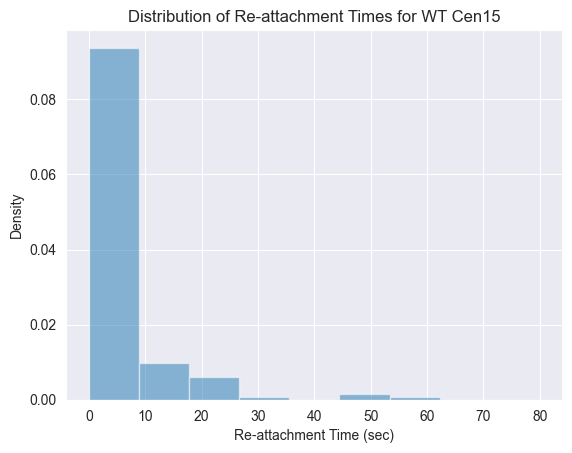

In [14]:
cen15_wt_reattachment_times = extract_no_tension_runs(wt_cen15_dfs)
plt.hist(cen15_wt_reattachment_times['run_duration_sec'], bins=np.linspace(0, 80, 10), density=True, alpha=0.5, label='WT Cen4');
plt.xlabel('Re-attachment Time (sec)')
plt.ylabel('Density')
plt.title('Distribution of Re-attachment Times for WT Cen15')

We perform a ttest to compare the re-attachment time distributions between WT Cen4 and WT Cen15. This shows that there is not a significant difference in the re-attachment time. 

In [15]:
from scipy.stats import ttest_ind
print(f"Mean re-attachment time for WT Cen4: {cen4_wt_reattachment_times['run_duration_sec'].mean():.2f} sec")
print(f"Mean re-attachment time for WT Cen15: {cen15_wt_reattachment_times['run_duration_sec'].mean():.2f} sec")
print(f"Mean re-attachment time for Cin8RK Cen4: {extract_no_tension_runs(cin8RK_cen4_dfs)['run_duration_sec'].mean():.2f} sec")
print(f"Mean re-attachment time for Cin8RK Cen15: {extract_no_tension_runs(cin8RK_cen15_dfs)['run_duration_sec'].mean():.2f} sec")
ttest_ind(cen4_wt_reattachment_times['run_duration_sec'], cen15_wt_reattachment_times['run_duration_sec'], alternative='two-sided')

Mean re-attachment time for WT Cen4: 5.14 sec
Mean re-attachment time for WT Cen15: 4.40 sec
Mean re-attachment time for Cin8RK Cen4: 5.62 sec
Mean re-attachment time for Cin8RK Cen15: 7.25 sec


TtestResult(statistic=np.float64(0.7409108680237351), pvalue=np.float64(0.45934492151522865), df=np.float64(291.0))

In [32]:
wt_reattachment_times = pd.concat([
    cen4_wt_reattachment_times.assign(Strain='WT'),
    # cen15_wt_reattachment_times.assign(Strain='WT')
])

cen4_cin8RK_reattachment_times = extract_no_tension_runs(cin8RK_cen4_dfs).assign(Strain='Cin8-RK kip1∆')
cen15_cin8RK_reattachment_times = extract_no_tension_runs(cin8RK_cen15_dfs).assign(Strain='Cin8-RK kip1∆')
cin8RK_reattachment_times = pd.concat([
    extract_no_tension_runs(cin8RK_cen4_dfs).assign(Strain='Cin8-RK kip1∆'),
    # extract_no_tension_runs(cin8RK_cen15_dfs).assign(Strain='Cin8-RK kip1∆')
])

reattachment_times = pd.concat([wt_reattachment_times, cin8RK_reattachment_times], ignore_index=True)

<Axes: xlabel='run_duration_sec', ylabel='Probability'>

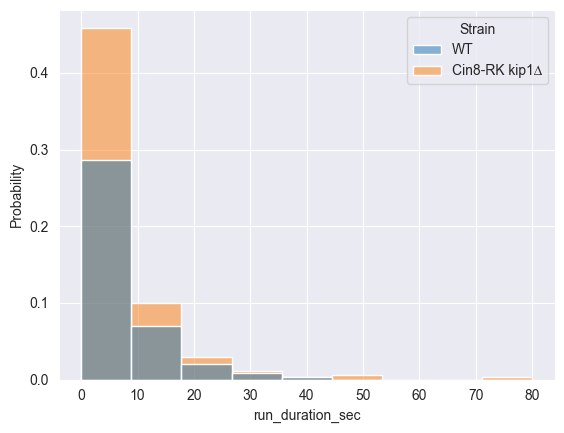

In [29]:
sns.histplot(data=reattachment_times.dropna(), x='run_duration_sec', hue='Strain', kde=False, stat='probability', bins=np.linspace(0, 80, 10))

Text(0.5, 1.0, 'Cin8-RK kip1∆ Re-attachment Times')

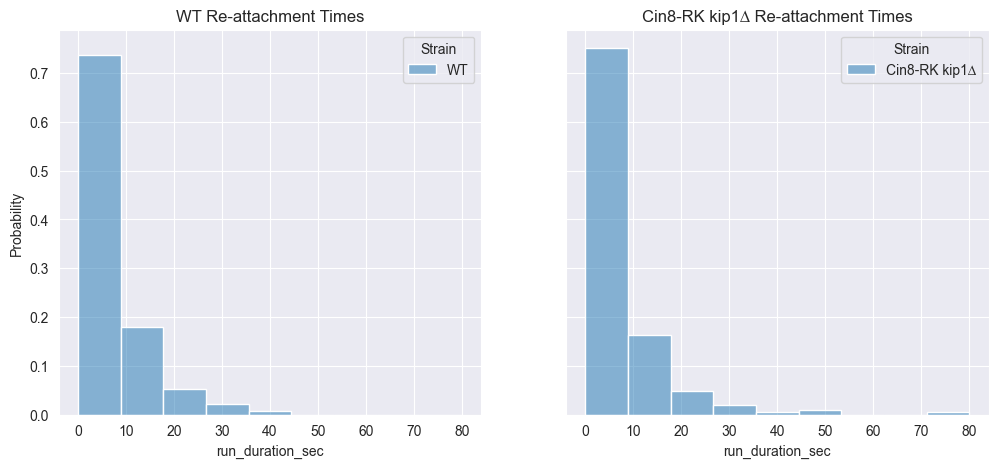

In [31]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
sns.histplot(data=wt_reattachment_times.dropna(), x='run_duration_sec', hue='Strain', kde=False, stat='probability', bins=np.linspace(0, 80, 10), ax=ax[0])
ax[0].set_title('WT Re-attachment Times')  

sns.histplot(data=cin8RK_reattachment_times.dropna(), x='run_duration_sec', hue='Strain', kde=False, stat='probability', bins=np.linspace(0, 80, 10), ax=ax[1])
ax[1].set_title('Cin8-RK kip1∆ Re-attachment Times')

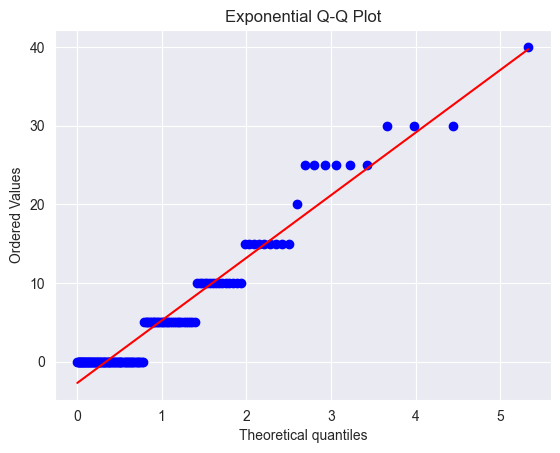

In [18]:
import matplotlib.pyplot as plt
from scipy import stats

# Generate a Q-Q plot against the exponential distribution
stats.probplot(reattachment_times[reattachment_times['Strain'] == 'WT']['run_duration_sec'].dropna(), dist="expon", plot=plt)
plt.title("Exponential Q-Q Plot")
plt.show()


In [34]:
import numpy as np
from scipy import stats

def compare_exponential_means(sample1, sample2):
    """
    Performs an exact F-test for the equality of means of two 
    independent exponential distributions.
    
    Parameters:
    sample1 (array-like): Observations from population 1
    sample2 (array-like): Observations from population 2
    
    Returns:
    dict: F-statistic, degrees of freedom, and p-value
    """
    n1 = len(sample1)
    n2 = len(sample2)
    
    # Calculate sample means
    mean1 = np.mean(sample1)
    mean2 = np.mean(sample2)
    
    # Test statistic is the ratio of the sample means: (mean1 / mean2)
    # Under H0, (mean1 / mean2) follows an F-distribution with (2*n1, 2*n2) degrees of freedom
    f_stat = mean1 / mean2
    
    # Degrees of freedom for the exact F-test
    df1 = 2 * n1
    df2 = 2 * n2
    
    # Two-sided p-value calculation using the F-distribution CDF
    p_value = 2 * min(stats.f.cdf(f_stat, df1, df2), 1 - stats.f.cdf(f_stat, df1, df2))
    
    return {
        "mean1": mean1,
        "mean2": mean2,
        "f_statistic": f_stat,
        "p_value": p_value
    }

print("CEN4 Re-attachment Times Comparison:")
compare_exponential_means(
    cen4_wt_reattachment_times['run_duration_sec'].dropna(),
    cen4_cin8RK_reattachment_times['run_duration_sec'].dropna()
)

CEN4 Re-attachment Times Comparison:


{'mean1': np.float64(5.13986013986014),
 'mean2': np.float64(5.622119815668203),
 'f_statistic': np.float64(0.9142210248767626),
 'p_value': np.float64(0.4110848915010122)}

There appears to be no difference in re-attachment times

In [35]:
print("CEN15 Re-attachment Times Comparison:")
compare_exponential_means(
    cen15_wt_reattachment_times['run_duration_sec'].dropna(),
    cen15_cin8RK_reattachment_times['run_duration_sec'].dropna()
)

CEN15 Re-attachment Times Comparison:


{'mean1': np.float64(4.4),
 'mean2': np.float64(7.254335260115607),
 'f_statistic': np.float64(0.6065338645418328),
 'p_value': np.float64(9.56847115163769e-06)}